In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# E-Commerce Sales & Customer Analytics

## Objective

Analyze e-commerce sales data to understand:
- Sales performance
- Customer behavior
- Product performance
- Trends over time
- Revenue patterns
- Business insights

## 2. Dataset Description

The dataset contains online retail transactions from a UK-based retailer.

Each row represents a transaction line containing information such as invoice number, product code, product description, quantity, invoice date, unit price, customer ID, and country.

The original dataset contains 541,909 rows and 8 columns.

The dataset was obtained from the UCI Machine Learning Repository's Online Retail dataset.

In [2]:
df = pd.read_excel('../data/Online Retail.xlsx')

In [3]:
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [8]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## 3. Data Quality Assessment

Initial inspection identified missing product descriptions, missing customer IDs, duplicate rows, negative quantities, zero-price records, and negative unit prices.

These issues require investigation before finalizing sales metrics.

Missing customer IDs are not automatically treated as invalid transactions because the records may still be useful for overall sales analysis. Negative quantities may represent returns or cancellations, while unusual prices require further investigation.

In [10]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(5268)

In [12]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [13]:
missing_percent = df.isnull().mean().mul(100).round(2)
print(missing_percent)

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [14]:
print("Minimum quantity:", df["Quantity"].min())
print("Maximum quantity:", df["Quantity"].max())
print("Negative quantity rows:", (df["Quantity"] < 0).sum())
print("Zero quantity rows:", (df["Quantity"] == 0).sum())

Minimum quantity: -80995
Maximum quantity: 80995
Negative quantity rows: 10624
Zero quantity rows: 0


In [15]:
print("Minimum unit price:", df["UnitPrice"].min())
print("Maximum unit price:", df["UnitPrice"].max())
print("Zero-price rows:", (df["UnitPrice"] == 0).sum())
print("Negative-price rows:", (df["UnitPrice"] < 0).sum())

Minimum unit price: -11062.06
Maximum unit price: 38970.0
Zero-price rows: 2515
Negative-price rows: 2


In [16]:
df.loc[
    df["Quantity"] < 0,
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "InvoiceDate", "UnitPrice"]
].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25


In [17]:
df.loc[
    df["UnitPrice"] < 0,
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "InvoiceDate", "UnitPrice"]
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06


In [18]:
df.loc[
    df["CustomerID"].isna(),
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "Country"]
].head(10)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
622,536414,22139,NaN,56,0.00,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2.51,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2.51,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,0.85,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,1.66,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,1.66,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2.51,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,0.43,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,0.43,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,0.43,United Kingdom


In [19]:
df_clean = df.copy()

In [ ]:
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)
print("Total line revenue:", df_clean["Revenue"].sum())
print(
    "Revenue from negative-quantity rows:",
    df_clean.loc[df_clean["Quantity"] < 0, "Revenue"].sum()
)
print(
    "Revenue from negative-price rows:",
    df_clean.loc[df_clean["UnitPrice"] < 0, "Revenue"].sum()
)

Total line revenue: 9747747.933999998
Revenue from negative-quantity rows: -896812.49
Revenue from negative-price rows: -22124.12


In [21]:
df_clean["IsCancellation"] = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

print(df_clean["IsCancellation"].value_counts())

IsCancellation
False    532621
True       9288
Name: count, dtype: int64


In [22]:
print("Original rows:", len(df_clean))

print("Exact duplicate rows:", df_clean.duplicated().sum())

print("Missing descriptions:", df_clean["Description"].isna().sum())

print("Missing customer IDs:", df_clean["CustomerID"].isna().sum())

print("Cancellation rows:", df_clean["IsCancellation"].sum())

print("Negative quantity rows:", (df_clean["Quantity"] < 0).sum())

print("Zero-price rows:", (df_clean["UnitPrice"] == 0).sum())

print("Negative-price rows:", (df_clean["UnitPrice"] < 0).sum())

Original rows: 541909
Exact duplicate rows: 5268
Missing descriptions: 1454
Missing customer IDs: 135080
Cancellation rows: 9288
Negative quantity rows: 10624
Zero-price rows: 2515
Negative-price rows: 2


In [23]:
# Record the row count before cleaning
rows_before = len(df_clean)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Calculate how many rows were removed
rows_removed = rows_before - len(df_clean)

print("Rows before cleaning:", rows_before)
print("Duplicate rows removed:", rows_removed)
print("Rows after cleaning:", len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())

Rows before cleaning: 541909
Duplicate rows removed: 5268
Rows after cleaning: 536641
Remaining duplicates: 0


In [24]:
df.shape
df_clean.shape

(536641, 10)

In [25]:
missing_desc = df_clean[df_clean["Description"].isna()]

missing_desc.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancellation
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,0.0,False
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,0.0,False
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0,False
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0,False
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0,False
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0,False
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0,False
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0,False
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0,False
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0,False


In [26]:
print("Rows with missing descriptions:", len(missing_desc))

print("Total revenue from these rows:",
      missing_desc["Revenue"].sum())

print("Missing-description rows with negative quantity:",
      (missing_desc["Quantity"] < 0).sum())

print("Missing-description rows with zero price:",
      (missing_desc["UnitPrice"] == 0).sum())

Rows with missing descriptions: 1454
Total revenue from these rows: 0.0
Missing-description rows with negative quantity: 862
Missing-description rows with zero price: 1454


In [27]:
missing_customer = df_clean[df_clean["CustomerID"].isna()]

print("Rows with missing CustomerID:", len(missing_customer))

print(
    "Rows with nonzero revenue:",
    (missing_customer["Revenue"] != 0).sum()
)

print(
    "Total revenue from rows with missing CustomerID:",
    missing_customer["Revenue"].sum()
)

Rows with missing CustomerID: 135037
Rows with nonzero revenue: 132567
Total revenue from rows with missing CustomerID: 1447487.53


In [28]:
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows remaining:", df_clean.duplicated().sum())

print("\nRevenue column exists:", "Revenue" in df_clean.columns)

Rows: 536641
Columns: 10

Missing values:
InvoiceNo              0
StockCode              0
Description         1454
Quantity               0
InvoiceDate            0
UnitPrice              0
CustomerID        135037
Country                0
Revenue                0
IsCancellation         0
dtype: int64

Duplicate rows remaining: 0

Revenue column exists: True


In [29]:
df_clean["Month"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

In [30]:
monthly_revenue = (
    df_clean.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

monthly_revenue

Month
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     681386.460
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432701.060
Freq: M, Name: Revenue, dtype: float64

In [31]:
best_month = monthly_revenue.idxmax()
best_revenue = monthly_revenue.max()

print("Highest-revenue month:", best_month)
print("Revenue:", round(best_revenue, 2))

Highest-revenue month: 2011-11
Revenue: 1456145.8


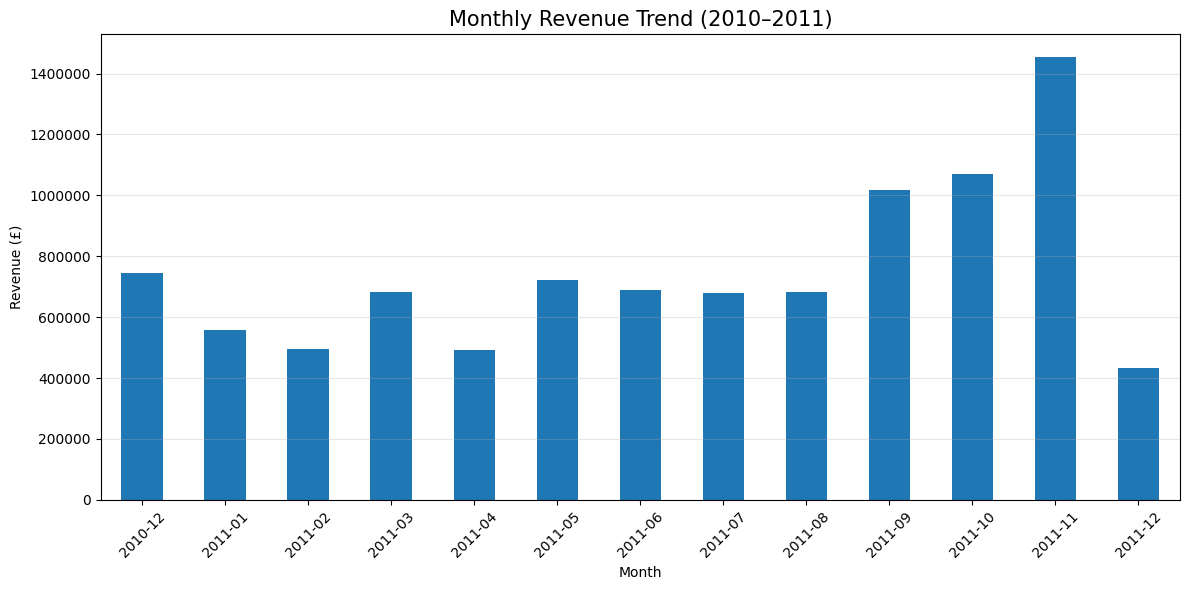

In [34]:
plt.figure(figsize=(12, 6))

monthly_revenue.plot(kind="bar")

plt.title("Monthly Revenue Trend (2010–2011)", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
monthly_revenue.sort_values(
    ascending=False
).head(3)

Month
2011-11    1456145.800
2011-10    1069368.230
2011-09    1017596.682
Freq: M, Name: Revenue, dtype: float64

## 4. Monthly Revenue Analysis

Monthly revenue is calculated by multiplying transaction quantity by unit price and aggregating the resulting values by month.

### Preliminary Findings

- November 2011 recorded the highest monthly revenue in the current analysis.
- Revenue increased from September through November 2011.
- December 2011 contains only partial-month data, so its total is not directly comparable with complete months.

These findings are preliminary because returns, cancellations, and unusual accounting records have not yet been fully addressed in the final revenue metric.

In [35]:
product_revenue = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)
product_revenue.head(10)

Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164459.49
WHITE HANGING HEART T-LIGHT HOLDER     99612.42
PARTY BUNTING                          98243.88
JUMBO BAG RED RETROSPOT                92175.79
RABBIT NIGHT LIGHT                     66661.63
POSTAGE                                66230.64
PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
ASSORTED COLOUR BIRD ORNAMENT          58792.42
CHILLI LIGHTS                          53746.66
Name: Revenue, dtype: float64

In [36]:
product_analysis = (
    df_clean.groupby("Description")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .sort_values("Total_Quantity", ascending=False)
)

product_analysis.head(10)

,Total_Quantity,Total_Revenue
Description,,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,53751,13560.09
JUMBO BAG RED RETROSPOT,47260,92175.79
POPCORN HOLDER,36322,33959.26
ASSORTED COLOUR BIRD ORNAMENT,36282,58792.42
PACK OF 72 RETROSPOT CAKE CASES,36016,21047.07
WHITE HANGING HEART T-LIGHT HOLDER,35298,99612.42
RABBIT NIGHT LIGHT,30631,66661.63
MINI PAINT SET VINTAGE,26437,16810.42
PACK OF 12 LONDON TISSUES,26299,7967.82


## 5. Product Performance Analysis

Products are compared using two measures: total recorded revenue and net recorded quantity.

These measures provide different perspectives on product performance. A product may rank highly by quantity without generating the highest revenue.

Non-product charges, such as postage, and transactions involving returns may affect product rankings and must be considered when interpreting the results.

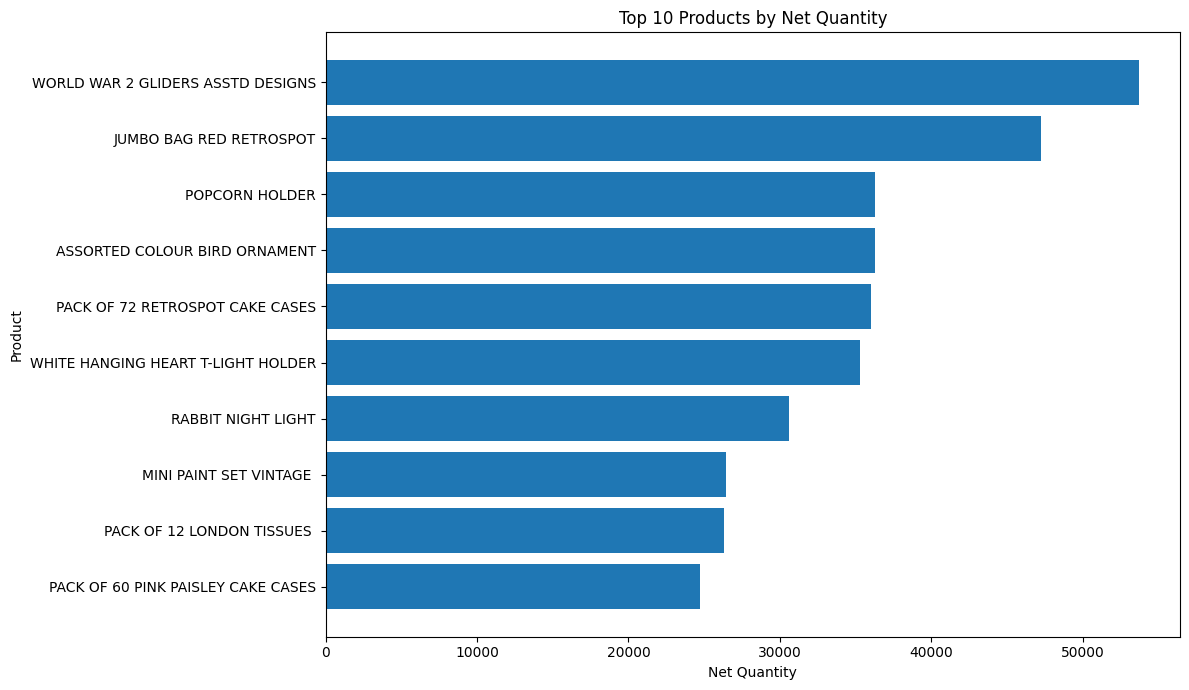

In [37]:
top_products = product_analysis.head(10).sort_values(
    "Total_Quantity"
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_products.index,
    top_products["Total_Quantity"]
)

plt.title("Top 10 Products by Net Quantity")
plt.xlabel("Net Quantity")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [38]:
country_analysis = (
    df_clean.groupby("Country")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

country_analysis.head(10)

,Total_Quantity,Total_Revenue,Unique_Customers
Country,,,
United Kingdom,4250328,8167128.184,3950
Netherlands,200128,284661.540,9
EIRE,142495,262993.380,3
Germany,117341,221509.470,95
France,110438,197317.110,87
Australia,83643,137009.770,9
Switzerland,30313,56363.050,21
Spain,26817,54756.030,31
Belgium,23152,40910.960,25


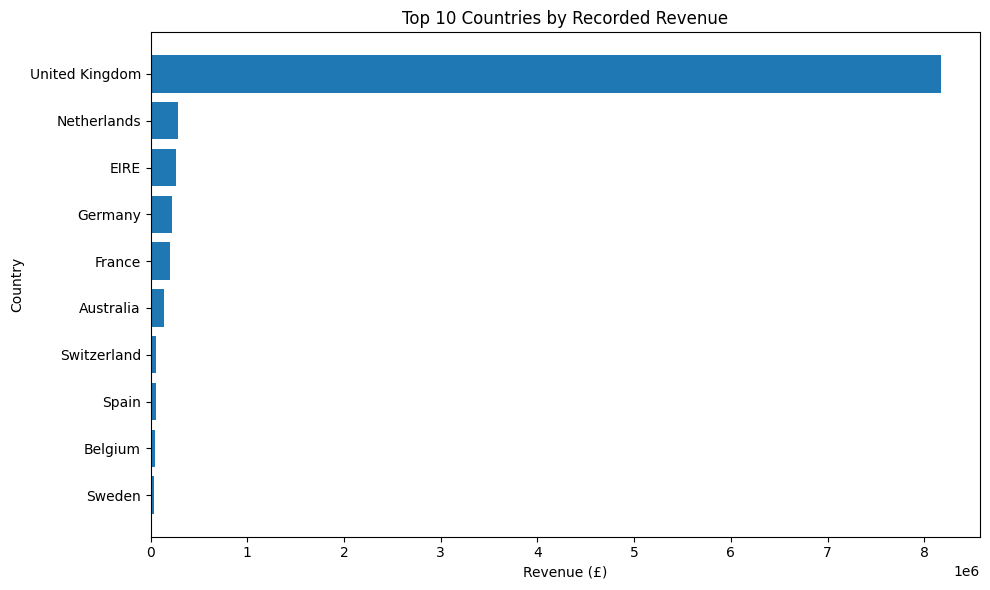

In [39]:
top_countries = (
    country_analysis.head(10)
    .sort_values("Total_Revenue")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries.index,
    top_countries["Total_Revenue"]
)

plt.title("Top 10 Countries by Recorded Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 6. Geographical Sales Analysis

Revenue, net quantity, and identifiable customer counts are aggregated by country to compare geographical sales performance.

The United Kingdom is the leading market by recorded revenue in the current analysis. Other countries, including the Netherlands, EIRE, Germany, and France, also contribute to recorded revenue.

Customer counts exclude missing customer IDs and should be interpreted alongside transaction revenue rather than used as a direct measure of market value.

In [41]:
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Rows:", len(df_clean))
print("Duplicate rows:", df_clean.duplicated().sum())
print("Total recorded revenue:", round(df_clean["Revenue"].sum(), 2))
print("Missing descriptions:", df_clean["Description"].isna().sum())
print("Missing customer IDs:", df_clean["CustomerID"].isna().sum())

Rows: 536641
Duplicate rows: 0
Total recorded revenue: 9726006.95
Missing descriptions: 1454
Missing customer IDs: 135037


## 7. Revenue Validation and Transaction Analysis

In this section, we examine cancellations, returns, and other transactions that may affect revenue calculations. The goal is to distinguish total recorded transaction value from revenue generated by regular sales.

In [42]:
# Check the transaction types in the dataset

print("Total rows:", len(df_clean))

print(
    "Cancellation invoices:",
    df_clean["IsCancellation"].sum()
)

print(
    "Negative quantity rows:",
    (df_clean["Quantity"] < 0).sum()
)

print(
    "Zero quantity rows:",
    (df_clean["Quantity"] == 0).sum()
)

print(
    "Zero unit price rows:",
    (df_clean["UnitPrice"] == 0).sum()
)

print(
    "Negative unit price rows:",
    (df_clean["UnitPrice"] < 0).sum()
)

Total rows: 536641
Cancellation invoices: 9251
Negative quantity rows: 10587
Zero quantity rows: 0
Zero unit price rows: 2510
Negative unit price rows: 2


In [43]:
# Separate cancellation invoices from other invoices

cancellations = df_clean[df_clean["IsCancellation"]]
other_transactions = df_clean[~df_clean["IsCancellation"]]

print(
    "Cancellation invoice value:",
    round(cancellations["Revenue"].sum(), 2)
)

print(
    "Other transaction value:",
    round(other_transactions["Revenue"].sum(), 2)
)

print(
    "Total recorded transaction value:",
    round(df_clean["Revenue"].sum(), 2)
)

Cancellation invoice value: -893979.73
Other transaction value: 10619986.68
Total recorded transaction value: 9726006.95


In [44]:
# Compare negative quantities across transaction types

negative_qty = df_clean[df_clean["Quantity"] < 0]

negative_qty_analysis = (
    negative_qty
    .groupby("IsCancellation")
    .agg(
        Transaction_Rows=("Quantity", "size"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
)

print(negative_qty_analysis)

                Transaction_Rows  Total_Quantity  Total_Revenue
IsCancellation                                                 
False                       1336         -206957           0.00
True                        9251         -275560     -893979.73


In [45]:
# Investigate negative quantities in non-cancellation invoices

negative_non_cancellation = df_clean[
    (df_clean["Quantity"] < 0) &
    (~df_clean["IsCancellation"])
]

print("Rows:", len(negative_non_cancellation))

print("\nUnit price statistics:")
print(negative_non_cancellation["UnitPrice"].describe())

print(
    "\nZero unit-price rows:",
    (negative_non_cancellation["UnitPrice"] == 0).sum()
)

print(
    "\nPositive unit-price rows:",
    (negative_non_cancellation["UnitPrice"] > 0).sum()
)

print(
    "\nNegative unit-price rows:",
    (negative_non_cancellation["UnitPrice"] < 0).sum()
)

print(
    "\nRevenue breakdown:"
)
print(
    negative_non_cancellation.groupby("UnitPrice")["Revenue"]
    .agg(["count", "sum"])
    .sort_values("sum")
    .head(10)
)

Rows: 1336

Unit price statistics:
count    1336.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: UnitPrice, dtype: float64

Zero unit-price rows: 1336

Positive unit-price rows: 0

Negative unit-price rows: 0

Revenue breakdown:
           count  sum
UnitPrice            
0.0         1336  0.0


In [46]:

# Investigate all zero-unit-price transactions

zero_price = df_clean[df_clean["UnitPrice"] == 0]

print("Total zero-price rows:", len(zero_price))

print("\nQuantity breakdown:")
print(
    zero_price["Quantity"]
    .value_counts()
    .sort_index()
)

print("\nTop product descriptions:")
print(
    zero_price["Description"]
    .value_counts()
    .head(15)
)

print("\nCancellation breakdown:")
print(
    zero_price["IsCancellation"]
    .value_counts()
)


Total zero-price rows: 2510

Quantity breakdown:
Quantity
-9600     2
-9058     1
-5368     1
-4830     1
-3667     1
         ..
 3000     1
 3100     1
 4000     1
 5568     1
 12540    1
Name: count, Length: 426, dtype: int64

Top product descriptions:
Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
Unsaleable, destroyed.             9
FRENCH BLUE METAL DOOR SIGN 1      9
thrown away                        9
amazon                             8
FRENCH BLUE METAL DOOR SIGN 8      8
Found                              8
FRENCH BLUE METAL DOOR SIGN 3      7
Name: count, dtype: int64

Cancellation breakdown:
IsCancellation
False    2510
Name: count, dtype: int64


In [47]:

# Inspect zero-price transactions with relevant columns

zero_price_sample = zero_price[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country",
        "Revenue"
    ]
]

print(zero_price_sample.head(20).to_string(index=False))


InvoiceNo StockCode Description  Quantity         InvoiceDate  UnitPrice  CustomerID        Country  Revenue
   536414     22139         NaN        56 2010-12-01 11:52:00        0.0         NaN United Kingdom      0.0
   536545     21134         NaN         1 2010-12-01 14:32:00        0.0         NaN United Kingdom      0.0
   536546     22145         NaN         1 2010-12-01 14:33:00        0.0         NaN United Kingdom      0.0
   536547     37509         NaN         1 2010-12-01 14:33:00        0.0         NaN United Kingdom      0.0
   536549    85226A         NaN         1 2010-12-01 14:34:00        0.0         NaN United Kingdom      0.0
   536550     85044         NaN         1 2010-12-01 14:34:00        0.0         NaN United Kingdom      0.0
   536552     20950         NaN         1 2010-12-01 14:34:00        0.0         NaN United Kingdom      0.0
   536553     37461         NaN         3 2010-12-01 14:35:00        0.0         NaN United Kingdom      0.0
   536554     84670

In [48]:

# Explore descriptions associated with zero-price records

print(
    zero_price.groupby("Description", dropna=False)
    .agg(
        Transaction_Rows=("Quantity", "size"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Transaction_Rows", ascending=False)
    .head(25)
    .to_string()
)


                                 Transaction_Rows  Total_Quantity
Description                                                      
NaN                                          1454          -13609
check                                         159          -12030
?                                              47           -1384
damages                                        45           -4338
damaged                                        43           -1632
found                                          25            1990
sold as set on dotcom                          20           -2393
adjustment                                     16             328
Damaged                                        14           -7540
thrown away                                     9           -4110
FRENCH BLUE METAL DOOR SIGN 1                   9              26
Unsaleable, destroyed.                          9          -15644
amazon                                          8             161
Found     

In [49]:
# Create a dataset for gross merchandise sales analysis

df_sales = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (~df_clean["IsCancellation"])
].copy()

# Calculate sales revenue
df_sales["SalesRevenue"] = (
    df_sales["Quantity"] * df_sales["UnitPrice"]
)

print("Original cleaned rows:", len(df_clean))
print("Sales transaction rows:", len(df_sales))
print("Excluded rows:", len(df_clean) - len(df_sales))

print(
    "Gross merchandise sales value: £",
    round(df_sales["SalesRevenue"].sum(), 2)
)

print("Missing descriptions:", df_sales["Description"].isna().sum())
print("Missing customer IDs:", df_sales["CustomerID"].isna().sum())


Original cleaned rows: 536641
Sales transaction rows: 524878
Excluded rows: 11763
Gross merchandise sales value: £ 10642110.8
Missing descriptions: 0
Missing customer IDs: 132186


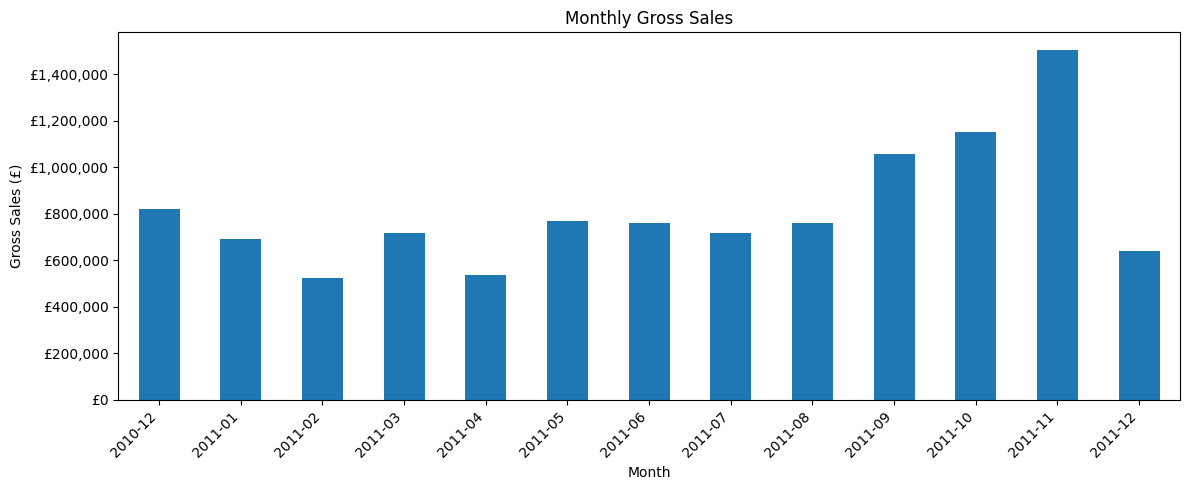

In [50]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Ensure InvoiceDate is datetime
df_sales["InvoiceDate"] = pd.to_datetime(df_sales["InvoiceDate"])

# Extract month and calculate monthly sales
df_sales["Month"] = df_sales["InvoiceDate"].dt.to_period("M")

monthly_sales = (
    df_sales.groupby("Month")["SalesRevenue"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 5))
monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(kind="bar")

plt.title("Monthly Gross Sales")
plt.xlabel("Month")
plt.ylabel("Gross Sales (£)")
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("£{x:,.0f}")
)
plt.tight_layout()

plt.savefig(
    "../visualization/monthly_gross_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


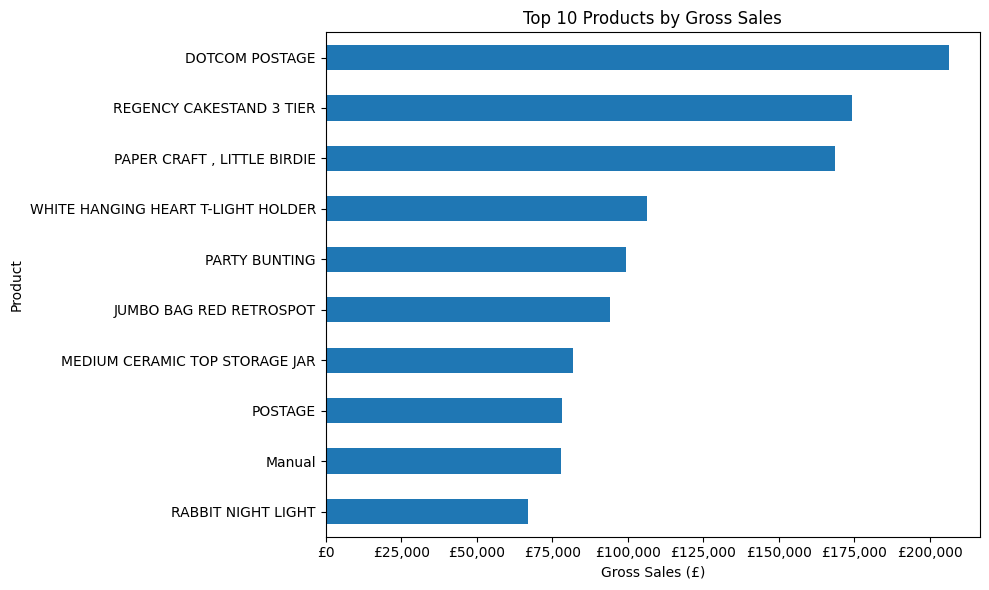

In [51]:

# Top 10 products by gross sales revenue

product_sales = (
    df_sales.groupby("Description")["SalesRevenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

product_sales.plot(kind="barh")

plt.title("Top 10 Products by Gross Sales")
plt.xlabel("Gross Sales (£)")
plt.ylabel("Product")

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("£{x:,.0f}")
)

plt.tight_layout()

plt.savefig(
    "../visualization/top_10_products_by_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


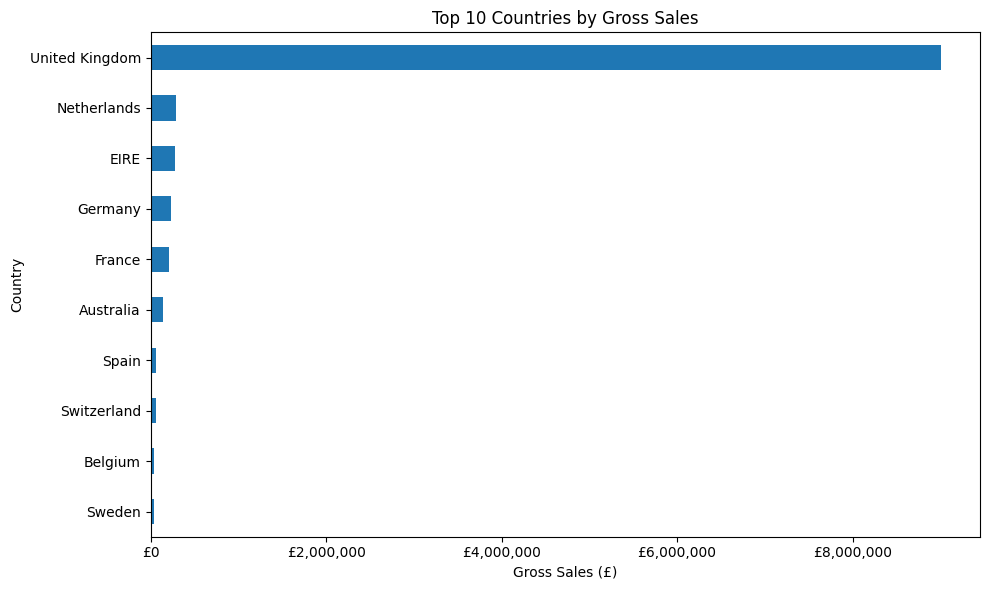

In [52]:

# Top 10 countries by gross sales

country_sales = (
    df_sales.groupby("Country")["SalesRevenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

country_sales.plot(kind="barh")

plt.title("Top 10 Countries by Gross Sales")
plt.xlabel("Gross Sales (£)")
plt.ylabel("Country")

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("£{x:,.0f}")
)

plt.tight_layout()

plt.savefig(
    "../visualization/top_10_countries_by_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


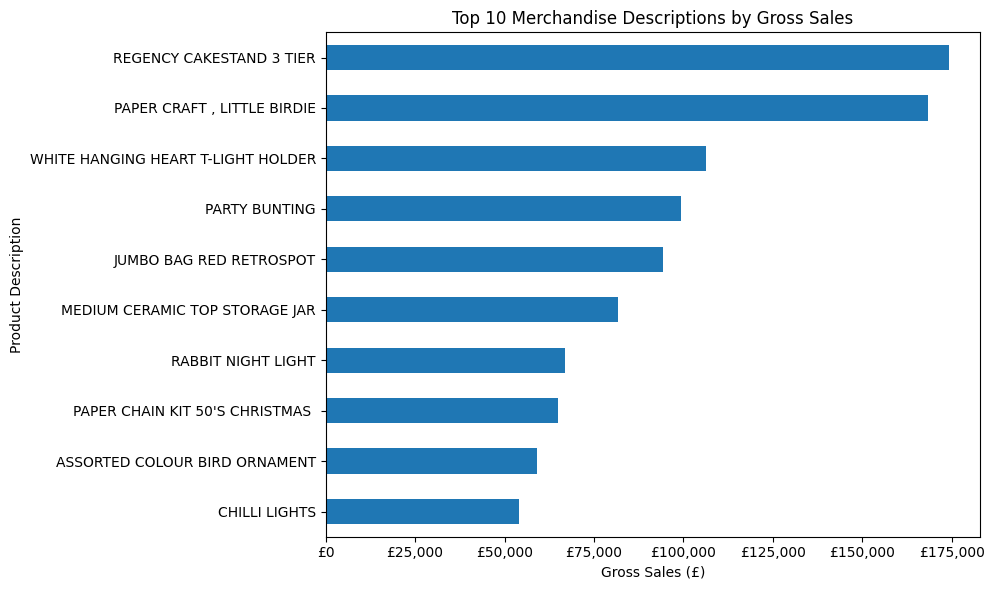

In [53]:

# Create a merchandise-focused product ranking

df_merchandise = df_sales.copy()

# Normalize descriptions for consistent filtering
df_merchandise["Description_Normalized"] = (
    df_merchandise["Description"]
    .str.strip()
    .str.upper()
)

# Exclude known postage and manual charge entries
non_merchandise = {
    "POSTAGE",
    "DOTCOM POSTAGE",
    "MANUAL"
}

df_merchandise = df_merchandise[
    ~df_merchandise["Description_Normalized"].isin(
        non_merchandise
    )
].copy()

top_products = (
    df_merchandise
    .groupby("Description")["SalesRevenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")

plt.title("Top 10 Merchandise Descriptions by Gross Sales")
plt.xlabel("Gross Sales (£)")
plt.ylabel("Product Description")

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("£{x:,.0f}")
)

plt.tight_layout()

plt.savefig(
    "../visualization/top_10_merchandise_by_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [54]:

# Top 10 countries by gross sales

country_summary = (
    df_sales.groupby("Country")
    .agg(
        Gross_Sales=("SalesRevenue", "sum"),
        Transaction_Rows=("InvoiceNo", "size"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .sort_values("Gross_Sales", ascending=False)
)

print(country_summary.head(10).round(2))


                Gross_Sales  Transaction_Rows  Unique_Customers
Country                                                        
United Kingdom   9001744.09            479985              3920
Netherlands       285446.34              2359                 9
EIRE              283140.52              7879                 3
Germany           228678.40              9025                94
France            209625.37              8392                87
Australia         138453.81              1181                 9
Spain              61558.56              2479                30
Switzerland        57067.60              1958                21
Belgium            41196.34              2031                25
Sweden             38367.83               450                 8


### Key Findings — Country-wise Sales

- The United Kingdom generated the highest gross sales among the countries analyzed, at approximately £9.00 million.
- The Netherlands and EIRE were the next-largest contributors, with approximately £285,446 and £283,141 in gross sales, respectively.
- Germany and France also contributed substantially to recorded sales.
- Customer counts vary considerably across countries, and missing customer IDs limit the completeness of customer-level comparisons.
- These figures represent gross sales from the selected transactions, not net revenue or profit. Returns, subsequent refunds, and non-merchandise charges require separate consideration.